# Exploratory Data Analysis (EDA)
We use charts to understand the data visually.
Each cell below draws one chart and saves it as a PNG file.

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

# load the master table
df = pd.read_csv('../data/master.csv', parse_dates=['order_purchase_timestamp'])

# create a year-month label like '2017-08' for grouping by month
df['year_month'] = df['order_purchase_timestamp'].dt.to_period('M').astype(str)

print(f'Loaded {len(df):,} rows')

Loaded 110,197 rows


## Chart 1 — Monthly Revenue Trend
Shows how total revenue changed month by month over time.

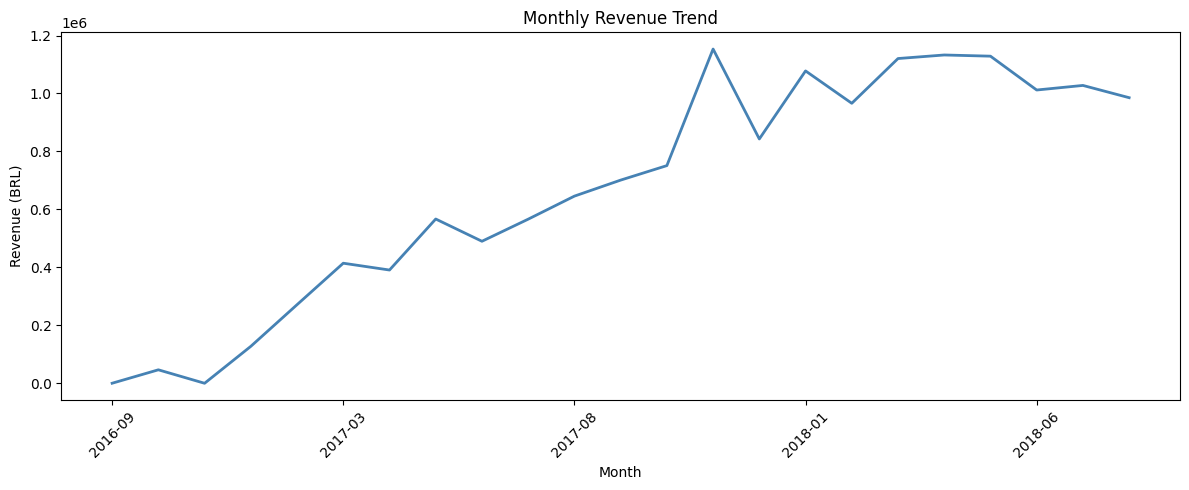

In [7]:
# group all sales by month and sum the revenue
monthly_revenue = df.groupby('year_month')['revenue'].sum()

fig, ax = plt.subplots(figsize=(12, 5))
monthly_revenue.plot(ax=ax, color='steelblue', linewidth=2)

ax.set_title('Monthly Revenue Trend')
ax.set_xlabel('Month')
ax.set_ylabel('Revenue (BRL)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../docs/chart_monthly_revenue.png', dpi=150)
plt.show()

## Chart 2 — Top 10 Product Categories
Shows which product categories bring in the most revenue.

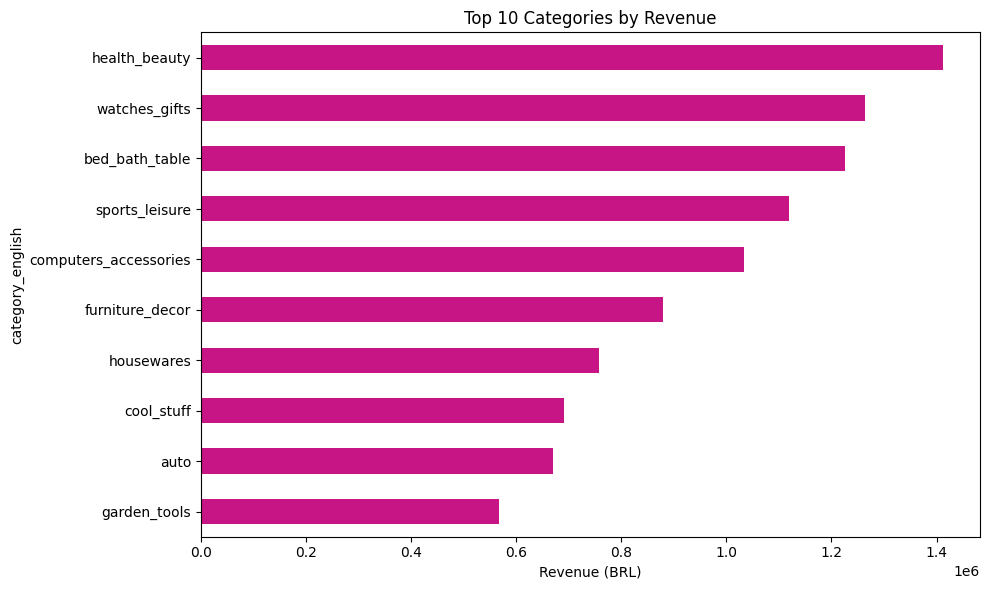

In [8]:
# get total revenue per category, pick top 10, sort for the chart
top_categories = (
    df.groupby('category_english')['revenue']
    .sum()
    .nlargest(10)
    .sort_values()   # sort ascending so the biggest bar is at the top
)

fig, ax = plt.subplots(figsize=(10, 6))
top_categories.plot(kind='barh', ax=ax, color='mediumvioletred')

ax.set_title('Top 10 Categories by Revenue')
ax.set_xlabel('Revenue (BRL)')
plt.tight_layout()
plt.savefig('../docs/chart_top_categories.png', dpi=150)
plt.show()

## Chart 3 — Top 10 States by Revenue
Shows which Brazilian states generate the most sales.

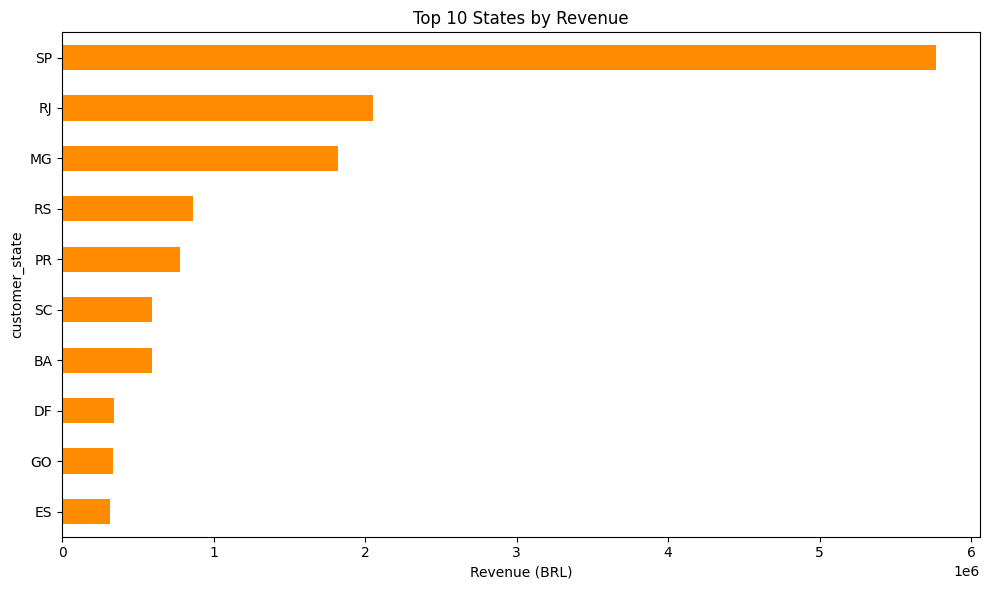

In [9]:
top_states = (
    df.groupby('customer_state')['revenue']
    .sum()
    .nlargest(10)
    .sort_values()
)

fig, ax = plt.subplots(figsize=(10, 6))
top_states.plot(kind='barh', ax=ax, color='darkorange')

ax.set_title('Top 10 States by Revenue')
ax.set_xlabel('Revenue (BRL)')
plt.tight_layout()
plt.savefig('../docs/chart_top_states.png', dpi=150)
plt.show()

## Chart 4 — Revenue by Day of Week
Shows if certain days of the week have more sales than others.

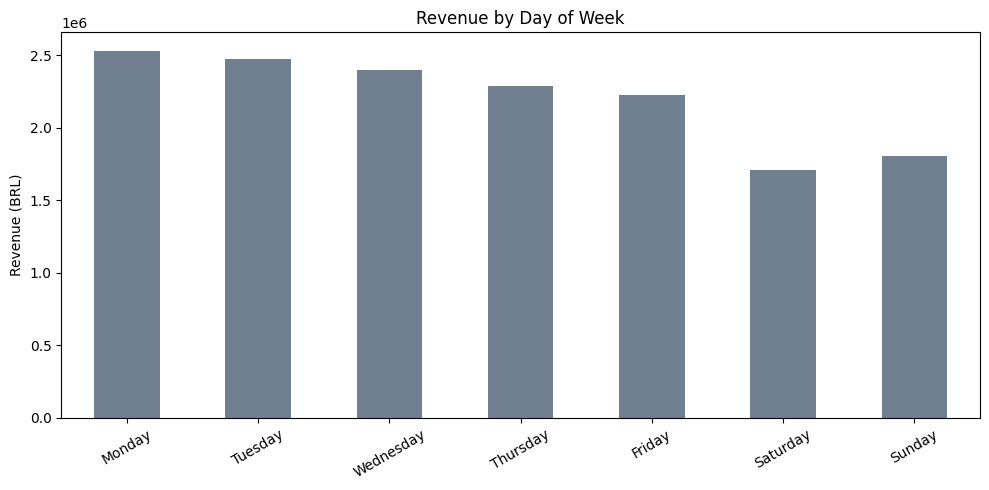

In [10]:
# define the correct weekday order (Mon to Sun)
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

weekday_revenue = (
    df.groupby('weekday')['revenue']
    .sum()
    .reindex(day_order)   # reorder so days appear Mon → Sun
)

fig, ax = plt.subplots(figsize=(10, 5))
weekday_revenue.plot(kind='bar', ax=ax, color='slategray')

ax.set_title('Revenue by Day of Week')
ax.set_ylabel('Revenue (BRL)')
ax.set_xlabel('')
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig('../docs/chart_weekday.png', dpi=150)
plt.show()